# sTEM data with IP effect

In [3]:
import numpy as np
from pytem import TEM
from pytem.temmodelling import modelTEMResIP
from pygimli.viewer.mpl.overlayimage import underlayBKGMap, underlayImageFile

In [4]:
thk = np.arange(2., 16, 2)
tem = TEM("zellwald2.xyz", thk=thk)
print(tem)

TEM profile with 20 soundings
29 times (1.232757e-05-0.002356259)


The file contains 104 soundings with 28 time gates between 10µs and 2ms, 8 for the low moment and 20 for the high moment.
First, we have a look into the transmitter waveforms.

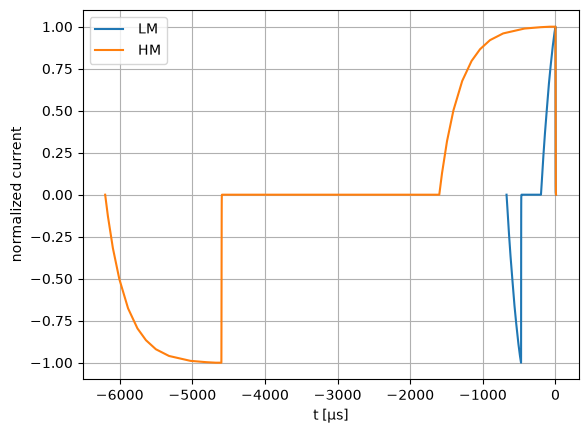

In [5]:
ax = tem.showWaveform();

While the high moment has a time interval of 4.6ms between shots of different polarity, it is 475µs for the low moment.
To have a closer look at the shutoff, one has to set the limits, showing a 2.5µs ramp for the low moment and a 5.5µs ramp for the high moment.

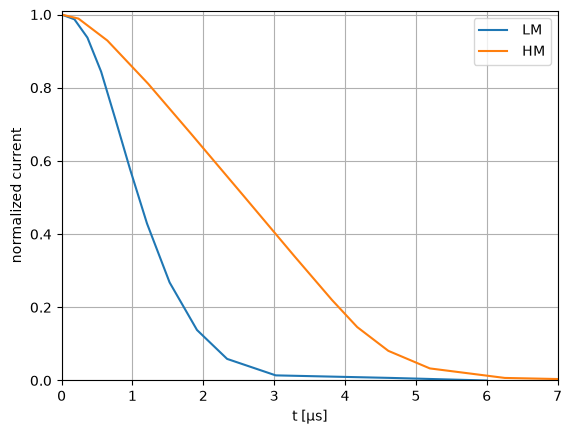

In [6]:
ax = tem.showWaveform(shutoff=True);
ax.set_xlim(0, 7); # now in µs

In the file, there are also the GPS positions that can be shown:

In [7]:
tem.filter(n=[0, 19])

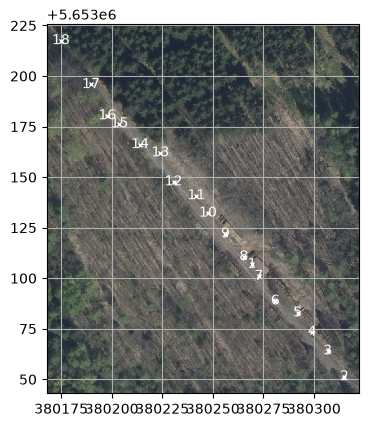

In [8]:
ax = tem.showPositions(every=1, color="white")
underlayImageFile(ax, "DOP380000,5652000,381000,5654000.jpg")

One sees that the GPS positions are rather inaccurate, i.e. the distances not equidistant and jumping from one side of the dirtroad to the other.

For a quick overview, one can plot the apparent resistivity in space, seeing that the sediment cover is most conductive (or thick) towards the end of the profile.

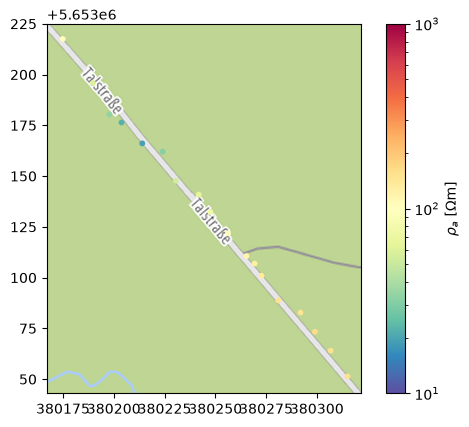

In [9]:
ax = tem.showRhoa(nt=4, orientation="vertical")
underlayBKGMap(ax, utmzone=33)

We can show a single sounding by

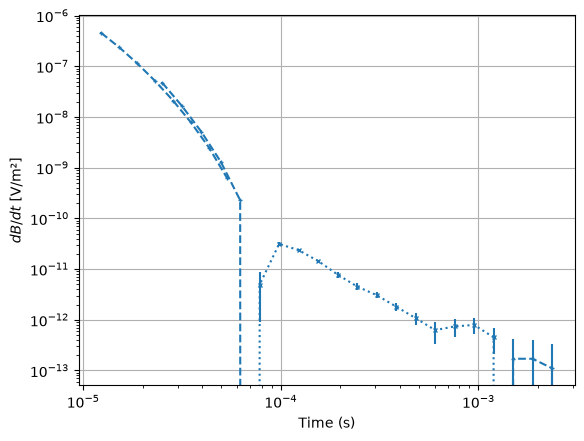

In [10]:
tem.showSounding(13);

and see a sign reversal at about 70µs. After 1ms, the signal runs into noise and the standard deviations are increasing. To check whether this is generally the case we can plot several soundings by (or all with no argument)

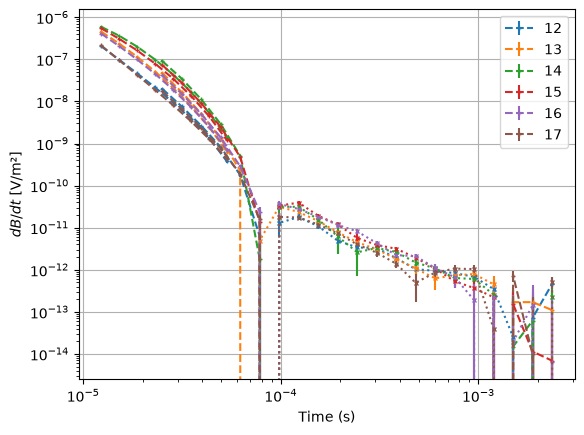

In [11]:
ax = tem.showSoundings(range(11, 17));
ax.legend();

The behavior is the same for all soundings, the position of the sign reversal changes slightly. Sounding 14 has the strongest signal corresponding with the apparent resistivity curve. We also cut the sounding above 1.5ms.

In [12]:
tem.filter(tmax=1.3e-3)

We try to model the subsurface by a two-layer model that we know from an ERT profile and compare it with a single sounding.

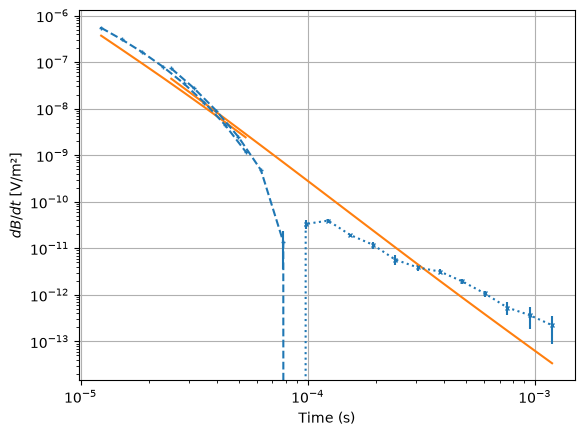

In [13]:
response = tem.simulate(rho=[50, 3000], thk=[20], show=15)

The model response fits at the early gates but cannot reproduce the sign change. This could be caused by 3D conductivity but the consistency speaks against it. Another explanation are induced polarization effects. So we model a conductivity using a well-known Cole-Cole model after Pelton et al. (1978), where besides resistivity a chargeability m, a time constant and an exponent is used.

$$
\rho^{\ast} = \rho^0 \left[1 - m \left(1 -  \frac{1}{1+(\imath\omega\tau)^c}\right) \right]
$$

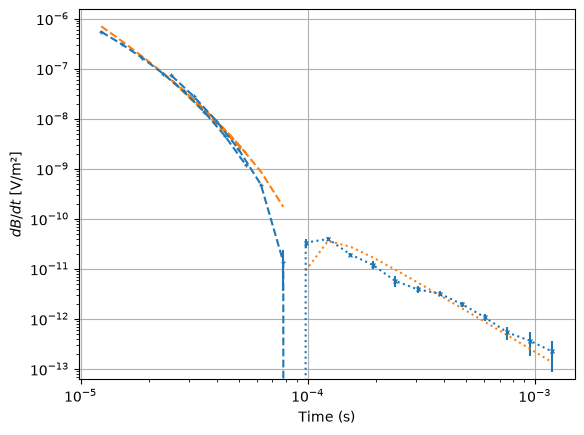

In [ ]:
resp = modelTEMResIP(
    cfg=tem.f.kw, thk=10,
    # res=[20, 3000], m=0.1, tau=3e-4, time=tem.t)
    res=[20.7, 10000], m=0.045, tau=2e-5, c=0.8, time=tem.t)
ax = tem.showSounding(15)
ax.plot(tem.t[resp>0], resp[resp>0], ls="--", color="C1")
ax.plot(tem.t[resp<0], -resp[resp<0], ls=":", color="C1");

At least we can reproduce a very similar curve, but it seems like the IP signal is too strong. Further parameter optimization is necessary.